# Практическая работа № 7 — Случайный лес
**Вариант A**

Сравним одиночное дерево и случайный лес на одной и той же задаче классификации.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


In [2]:
candidates = [Path("data/tips_sample.csv"), Path("../data/tips_sample.csv")]
df = pd.read_csv(next(p for p in candidates if p.exists())).dropna(subset=["total_bill"]).copy()
df["high_bill"] = (df["total_bill"] > df["total_bill"].median()).astype(int)
X = df.drop(columns=["high_bill", "total_bill"])
y = df["high_bill"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = ["size", "tip"]
cat_cols = ["day", "time"]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)


In [3]:
tree = DecisionTreeClassifier(random_state=42, max_depth=4)
forest = RandomForestClassifier(n_estimators=100, random_state=42)
tree.fit(X_train_p, y_train)
forest.fit(X_train_p, y_train)
tree_pred = tree.predict(X_test_p)
forest_pred = forest.predict(X_test_p)

comparison = pd.DataFrame([
    {"Модель": "DecisionTreeClassifier", "Accuracy": accuracy_score(y_test, tree_pred), "F1": f1_score(y_test, tree_pred, zero_division=0)},
    {"Модель": "RandomForestClassifier (100 деревьев)", "Accuracy": accuracy_score(y_test, forest_pred), "F1": f1_score(y_test, forest_pred, zero_division=0)}
])
display(comparison)


,Модель,Accuracy,F1
0,DecisionTreeClassifier,0.75000,0.777778
1,RandomForestClassifier (100 деревьев),0.84375,0.848485


,Признак,Важность
1,num__tip,0.731189
0,num__size,0.132734
7,cat__time_Lunch,0.030531
6,cat__time_Dinner,0.026867
5,cat__day_Thur,0.024386
3,cat__day_Sat,0.020104
2,cat__day_Fri,0.018836
4,cat__day_Sun,0.015354


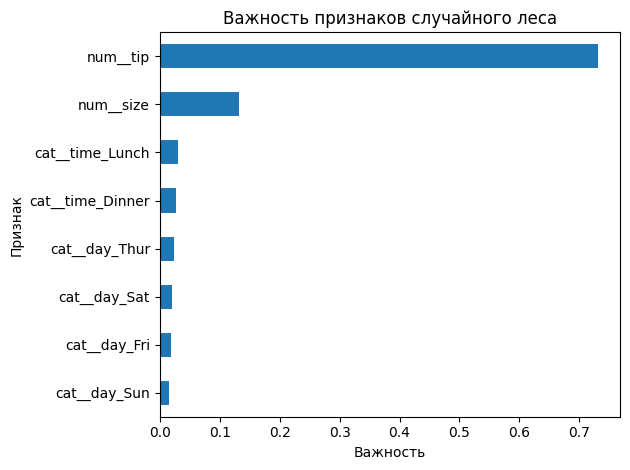

Два наиболее важных признака:


,Признак,Важность
1,num__tip,0.731189
0,num__size,0.132734


In [4]:
feature_names = preprocessor.get_feature_names_out()
importances = forest.feature_importances_
importance_df = pd.DataFrame({"Признак": feature_names, "Важность": importances}).sort_values("Важность", ascending=False)
display(importance_df)
importance_df.sort_values("Важность").plot(kind="barh", x="Признак", y="Важность", legend=False)
plt.title("Важность признаков случайного леса")
plt.xlabel("Важность")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()
print("Два наиболее важных признака:")
display(importance_df.head(2))


## Вывод
Метрики двух моделей рассчитаны на одинаковой тестовой выборке. Случайный лес использует 100 деревьев. Важность признака показывает его вклад в работу модели, но не доказывает причинно-следственную связь.